# Figure 3: descriptive environmental embedding space
Section 2.7: L2-normalised CLIP embeddings, 32-component PCA, 50 neighbours, and 60 MiniBatch k-means clusters (seed 7). Frames inherit STCoV from their bouts. No independent-frame significance tests are performed.

The original code calculated the 75th percentile after joining frames (frame-weighted). That convention is retained to preserve the source figure analysis; the manuscript's bout-level wording is ambiguous. There is no explicit free-living/cohort time filter in the original embedding analysis. Representatives below are the nearest frames to centroids of the three lowest- and three highest-prevalence clusters; exact hand-selected manuscript images/annotations were not saved.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans
from sklearn.neighbors import NearestNeighbors
from IPython.display import display
from matplotlib.ticker import PercentFormatter

plt.style.use("ggplot")
pd.set_option('display.max_columns', 200)
pd.set_option('display.max_colwidth', 140)

EMB_PATH = Path('derived/frame_embeddings.parquet')
FRAMES_PATH = Path('derived/frames.parquet')
BOUTS_PATH = Path('derived/bouts.parquet')

for p in [EMB_PATH, FRAMES_PATH, BOUTS_PATH]:
    if not p.exists():
        raise FileNotFoundError(p)

In [2]:
emb = pd.read_parquet(EMB_PATH, columns=['Participant', 'BoutIndex', 'FrameIndex', 'EmbeddingDim', 'Embedding'])

frames = pd.read_parquet(FRAMES_PATH, columns=[ 
    'Participant', 'BoutIndex', 'FrameIndex', 'RawMaskPath', 'ObjectNames',
    'ClutterIndex', 'PathObstructionIndex', 'TightCorridorIndex',
    'VisibleOpenFloorRatio', 'CentralCorridorOccupancy', 'WallAreaRatio',
],)

bouts = pd.read_parquet(BOUTS_PATH, columns=['Participant', 'BoutIndex', 'BoutStepTCV'],)
df = emb.merge(frames, on=['Participant', 'BoutIndex', 'FrameIndex'], how='left').merge(bouts, on=['Participant', 'BoutIndex'], how='left')
df = df.dropna(subset=['BoutStepTCV']).copy()

# Stabilize extreme scale in tight-corridor metric.
df['TightCorridorLog'] = np.log1p(df['TightCorridorIndex'].clip(lower=0))

summary = {
    'rows_joined': int(len(df)),
    'participants': int(df['Participant'].nunique()),
    'embedding_dim_values': df['EmbeddingDim'].value_counts().to_dict(),
    'null_rawmaskpath_rate': float(df['RawMaskPath'].isna().mean()),
    'null_objectnames_rate': float(df['ObjectNames'].isna().mean()),
}
summary


{'rows_joined': 94781,
 'participants': 39,
 'embedding_dim_values': {512: 94781},
 'null_rawmaskpath_rate': 0.025163271119739188,
 'null_objectnames_rate': 0.0}

In [3]:
var_q75 = df['BoutStepTCV'].quantile(0.75)
df['HighVAR'] = df['BoutStepTCV'] >= var_q75
print('Frame-weighted STCoV threshold:', var_q75)

Frame-weighted STCoV threshold: 0.13576753333104666


## 2) Build embedding geometry

We L2-normalize embeddings and reduce to 32 PCs for scalable neighborhood and region analysis.


In [4]:
X = np.vstack(df['Embedding'].to_numpy()).astype(np.float32)
X = X / np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-8, None)

pca = PCA(n_components=32, svd_solver='randomized', random_state=7)
Z = pca.fit_transform(X)

# Keep 2D projection for visualization only.
pca2 = PCA(n_components=2, svd_solver='randomized', random_state=7)
Z2 = pca2.fit_transform(X)

df['PC1'] = Z2[:, 0]
df['PC2'] = Z2[:, 1]

{
    'n_rows': int(Z.shape[0]),
    'pca32_explained_variance': float(pca.explained_variance_ratio_.sum()),
    'pca2_explained_variance': float(pca2.explained_variance_ratio_.sum()),
}


{'n_rows': 94781,
 'pca32_explained_variance': 0.7031415700912476,
 'pca2_explained_variance': 0.25032007694244385}

## Local prevalence and cluster summaries

In [5]:
k = 50
nn = NearestNeighbors(n_neighbors=k+1, metric='euclidean', n_jobs=-1).fit(Z)

# Exclude each query's own index explicitly, including tied embeddings.
raw_neighbors = nn.kneighbors(Z,return_distance=False)
neighbor_idx = np.array([row[row != i][:k] for i,row in enumerate(raw_neighbors)])

labels = df['HighVAR'].to_numpy(dtype=np.int8)
df['LocalHighVARRate'] = labels[neighbor_idx].mean(axis=1)

n_clusters = 60
kmeans = MiniBatchKMeans(n_clusters=n_clusters,random_state=7,batch_size=4096,n_init='auto')
df['Cluster'] = kmeans.fit_predict(Z)
cluster_stats = df.groupby('Cluster',as_index=False).agg(n=('Cluster','size'),high_rate=('HighVAR','mean'),variability_mean=('BoutStepTCV','mean'))
base_rate = float(labels.mean())

display(cluster_stats.sort_values('high_rate'))

,Cluster,n,high_rate,variability_mean
46,46,2111,0.003790,0.043552
25,25,1903,0.004729,0.067042
16,16,1128,0.007979,0.055720
17,17,1580,0.019620,0.065358
57,57,2294,0.021360,0.062672
9,9,2159,0.045855,0.075037
31,31,2160,0.047222,0.072061
19,19,1407,0.050462,0.090194
52,52,1605,0.051090,0.076058
37,37,903,0.055371,0.091031


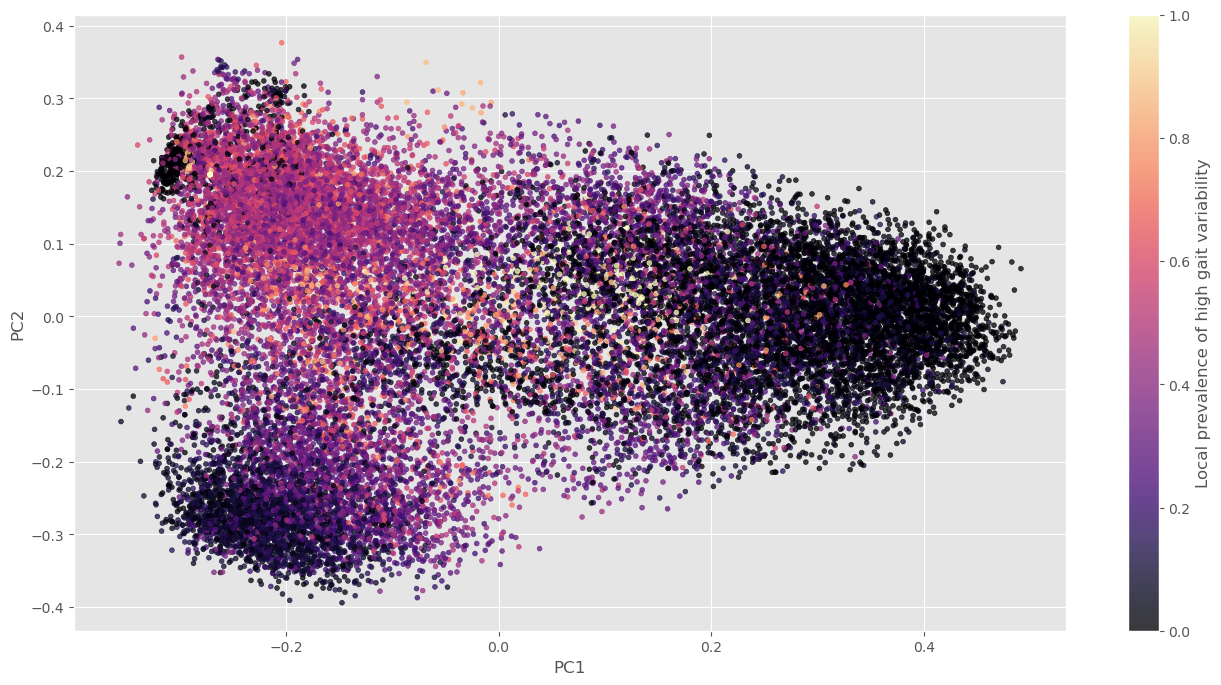

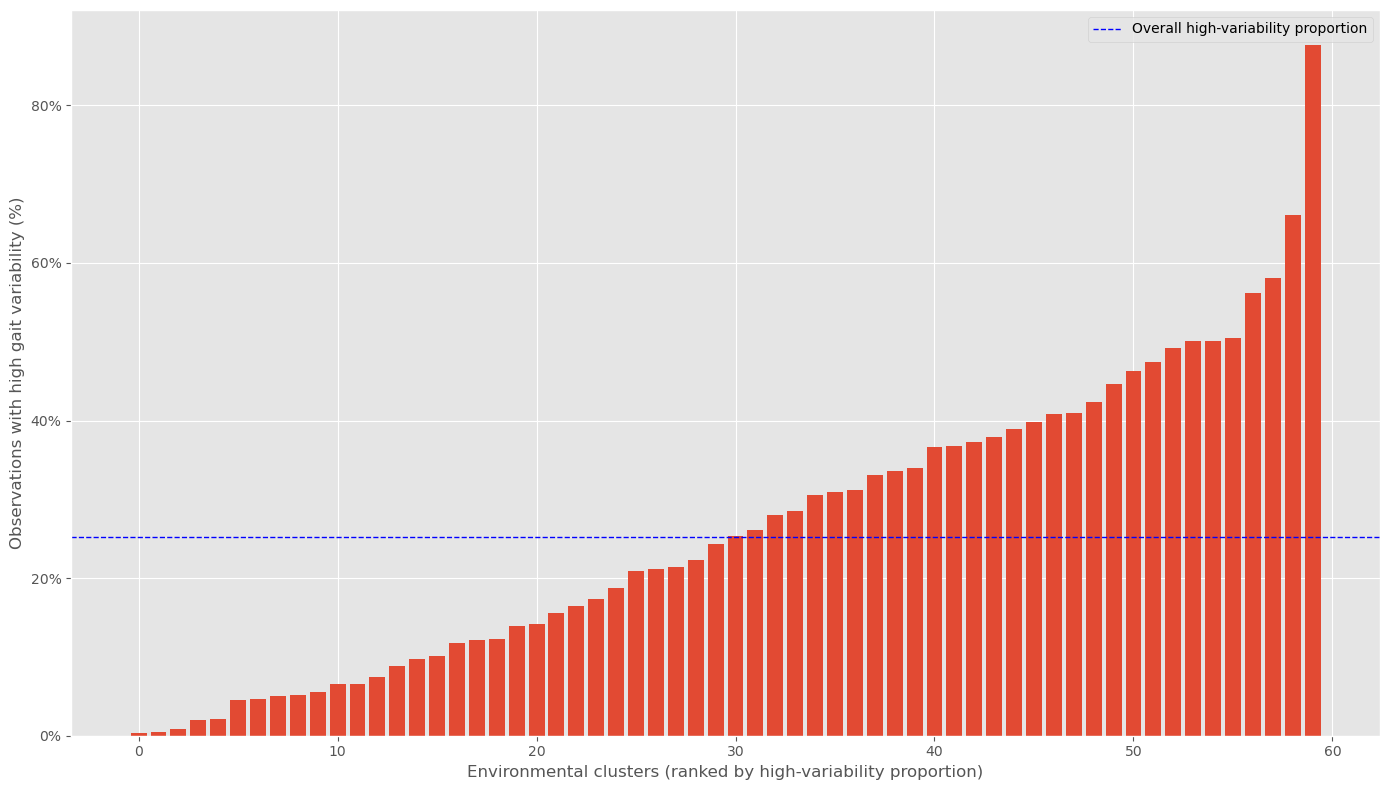

In [6]:
# Visual summary: local enrichment map and cluster high-rate distribution.
sample = df.sample(n=min(len(df), 25000), random_state=7)

Path('results').mkdir(exist_ok=True)
fig = plt.figure(figsize=(16, 8))
ax = fig.gca()
sc = ax.scatter(sample['PC1'], sample['PC2'], c=sample["LocalHighVARRate"], s=12, cmap='magma', alpha=0.75)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
plt.colorbar(sc, ax=ax, label='Local prevalence of high gait variability')

fig.savefig('results/figure3A.png',dpi=160,bbox_inches='tight')
fig = plt.figure(figsize=(14, 8))
ax = fig.gca()
sorted_rates = cluster_stats.sort_values('high_rate')['high_rate'].to_numpy()
ax.bar(np.arange(len(sorted_rates)), height=sorted_rates,)

ax.axhline(base_rate, linestyle='--', linewidth=1, c="blue", label='Overall high-variability proportion')
ax.set_xlabel('Environmental clusters (ranked by high-variability proportion)')
ax.set_ylabel('Observations with high gait variability (%)')

ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend()

plt.tight_layout()
fig.savefig('results/figure3B.png',dpi=160,bbox_inches='tight')
plt.show()


## Centroid-nearest representatives

In [7]:
ranked = cluster_stats.sort_values(['high_rate','Cluster'])
selected = pd.concat([ranked.head(3).assign(Region='Low variability'),ranked.tail(3).assign(Region='High variability')])
rows = []

for cluster in selected.itertuples():
    indices = np.flatnonzero(df.Cluster.to_numpy()==cluster.Cluster)
    distances = np.linalg.norm(Z[indices]-kmeans.cluster_centers_[cluster.Cluster],axis=1)
    chosen = indices[np.argsort(distances,kind='stable')[:3]]
    examples = df.iloc[chosen][['Participant','BoutIndex','FrameIndex','RawMaskPath','BoutStepTCV','ObjectNames']].copy()
    examples['Cluster'] = cluster.Cluster
    examples['Region'] = cluster.Region
    rows.append(examples)

representatives = pd.concat(rows,ignore_index=True)
display(representatives)

Path('results').mkdir(exist_ok=True)
cluster_stats.to_csv('results/figure3_clusters.csv',index=False)
representatives.to_csv('results/figure3_representatives.csv',index=False)

,Participant,BoutIndex,FrameIndex,RawMaskPath,BoutStepTCV,ObjectNames,Cluster,Region
0,UFALL_PD_0003,152,34545,OUTPUTS/Masks/UFALL_PD_0003/bout_152/frame_187869_mask.npy,0.036381,"car, curb, grass, gravel, pavement, wall",46,Low variability
1,UFALL_PD_0003,152,36510,OUTPUTS/Masks/UFALL_PD_0003/bout_152/frame_189834_mask.npy,0.036381,"bin, curb, grass, ground, pavement, wall",46,Low variability
2,UFALL_PD_0003,152,36270,OUTPUTS/Masks/UFALL_PD_0003/bout_152/frame_189594_mask.npy,0.036381,"car, curb, grass, gravel, pavement, wall",46,Low variability
3,UFALL_CL_0010,135,735,OUTPUTS/Masks/UFALL_CL_0010/bout_135/frame_243198_mask.npy,0.043459,"clothes, dog, grass, ground, pavement, person",25,Low variability
4,UFALL_CL_0010,143,4935,OUTPUTS/Masks/UFALL_CL_0010/bout_143/frame_260533_mask.npy,0.061667,"clothes, dog, grass, ground, person",25,Low variability
5,UFALL_CL_0010,141,405,OUTPUTS/Masks/UFALL_CL_0010/bout_141/frame_251946_mask.npy,0.031799,"cable, clothes, dog, grass, ground, pavement, person, shoes, wall",25,Low variability
6,UFALL_PD_0004,141,2175,OUTPUTS/Masks/UFALL_PD_0004/bout_141/frame_193555_mask.npy,0.047138,"bag, cable, clothes, dog, grass, ground, person, shoes",16,Low variability
7,UFALL_PD_0004,118,1080,OUTPUTS/Masks/UFALL_PD_0004/bout_118/frame_169877_mask.npy,0.036366,"clothes, dog, grass, pavement, person",16,Low variability
8,UFALL_PD_0004,135,1065,OUTPUTS/Masks/UFALL_PD_0004/bout_135/frame_183063_mask.npy,0.078666,"clothes, dog, grass, ground, pavement, person, shoes",16,Low variability
9,UFALL_PD_0003,269,165,OUTPUTS/Masks/UFALL_PD_0003/bout_269/frame_324985_mask.npy,0.138193,"chair, clothes, door, doorway, floor, person, wall",26,High variability
